In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Settings
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

# Load all 8 tables
orders    = pd.read_csv('olist_orders_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
items     = pd.read_csv('olist_order_items_dataset.csv')
products  = pd.read_csv('olist_products_dataset.csv')
sellers   = pd.read_csv('olist_sellers_dataset.csv')
payments  = pd.read_csv('olist_order_payments_dataset.csv')
reviews   = pd.read_csv('olist_order_reviews_dataset.csv')
geo       = pd.read_csv('olist_geolocation_dataset.csv')

print('All datasets loaded successfully')
print(f'Orders: {len(orders):,} rows')
print(f'Customers: {len(customers):,} rows')
print(f'Order Items: {len(items):,} rows')

All datasets loaded successfully
Orders: 99,441 rows
Customers: 99,441 rows
Order Items: 112,650 rows


In [2]:
# Convert date columns
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

# Keep only delivered orders
orders_clean = orders[orders['order_status'] == 'delivered'].copy()

# Feature engineering
orders_clean['delivery_days'] = (
    orders_clean['order_delivered_customer_date'] -
    orders_clean['order_purchase_timestamp']).dt.days

orders_clean['is_late'] = (
    orders_clean['order_delivered_customer_date'] >
    orders_clean['order_estimated_delivery_date'])

orders_clean['month'] = orders_clean['order_purchase_timestamp'].dt.to_period('M')

print(f'Delivered orders: {len(orders_clean):,}')
print(f'Late orders: {orders_clean["is_late"].sum():,}')
print(f'Late %: {orders_clean["is_late"].mean()*100:.2f}%')
print(f'Avg delivery days: {orders_clean["delivery_days"].mean():.1f}')

Delivered orders: 96,478
Late orders: 7,826
Late %: 8.11%
Avg delivery days: 12.1


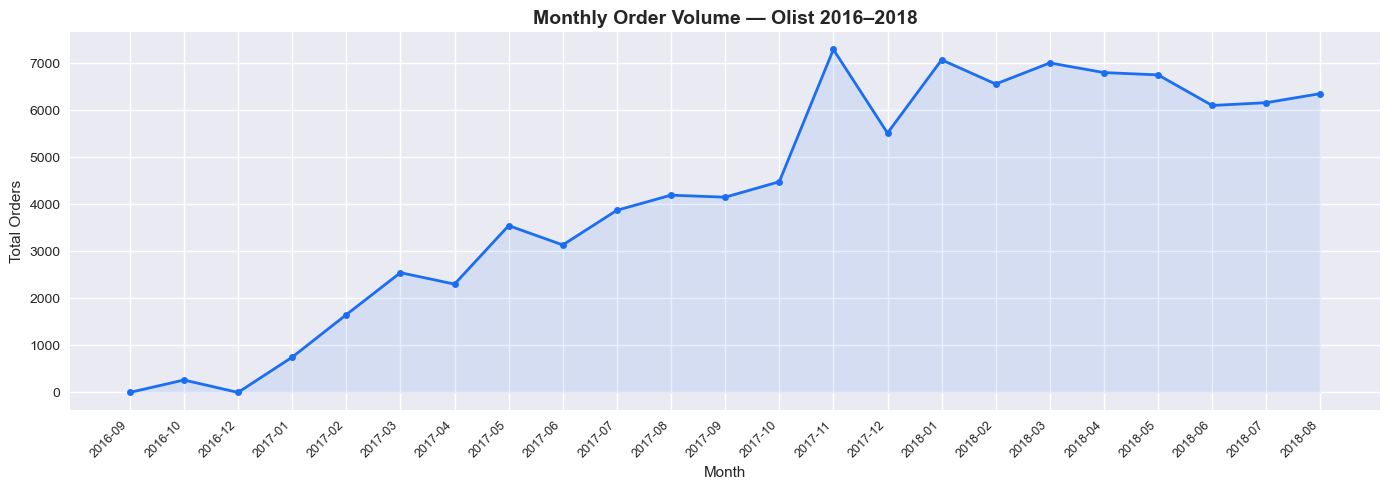

Chart 1 saved


In [3]:
# Chart 1 — Monthly orders trend
monthly_orders = orders_clean.groupby('month').size().reset_index(name='total_orders')
monthly_orders['month_str'] = monthly_orders['month'].astype(str)

plt.figure(figsize=(14, 5))
plt.plot(monthly_orders['month_str'], monthly_orders['total_orders'], 
         marker='o', linewidth=2, markersize=5, color='#1B6EF3')
plt.fill_between(range(len(monthly_orders)), monthly_orders['total_orders'], 
                 alpha=0.1, color='#1B6EF3')
plt.xticks(range(len(monthly_orders)), monthly_orders['month_str'], 
           rotation=45, ha='right', fontsize=9)
plt.title('Monthly Order Volume — Olist 2016–2018', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Orders')
plt.tight_layout()
plt.savefig('chart1_monthly_orders.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 1 saved')

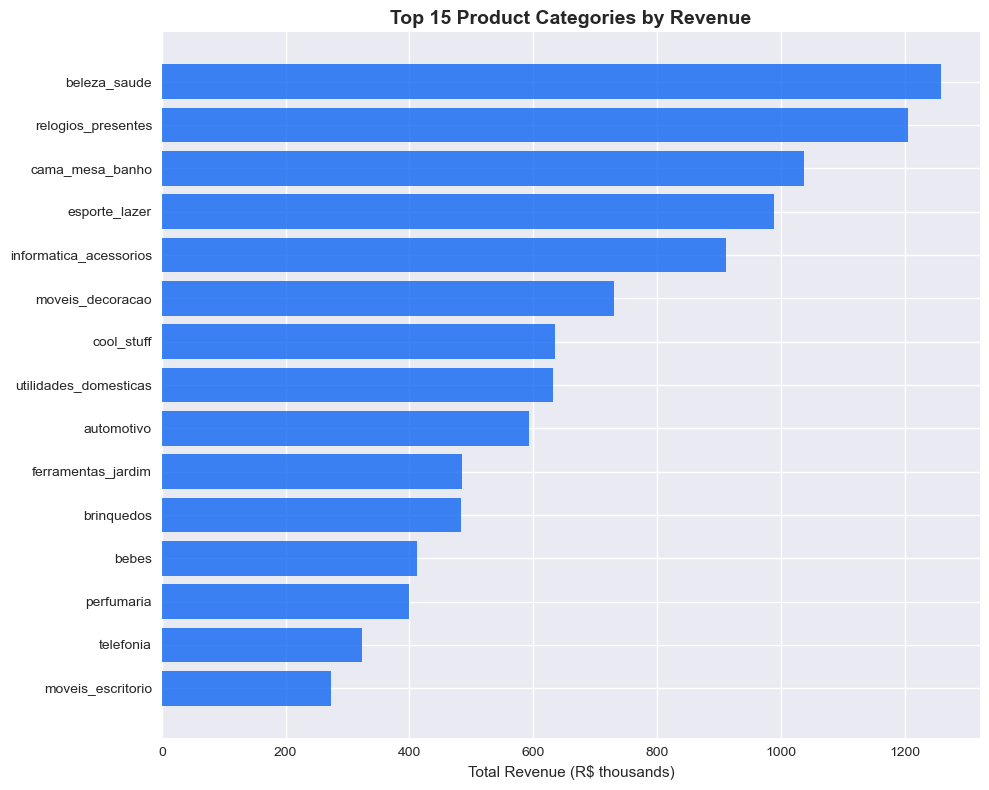

Chart 2 saved


In [4]:
# Chart 2 — Top 15 categories by revenue
cat_revenue = items.merge(products, on='product_id')
cat_revenue = cat_revenue.groupby('product_category_name')['price'].sum().reset_index()
cat_revenue = cat_revenue.sort_values('price', ascending=True).tail(15)

plt.figure(figsize=(10, 8))
bars = plt.barh(cat_revenue['product_category_name'], 
                cat_revenue['price'] / 1000,
                color='#1B6EF3', alpha=0.85)
plt.xlabel('Total Revenue (R$ thousands)')
plt.title('Top 15 Product Categories by Revenue', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('chart2_category_revenue.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 2 saved')

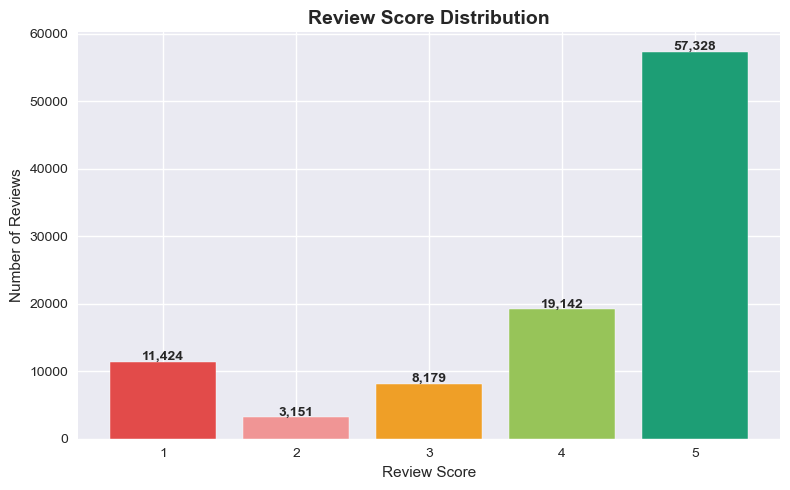

Chart 3 saved


In [5]:
# Chart 3 — Review score distribution
review_counts = reviews['review_score'].value_counts().sort_index()
colors = ['#E24B4A', '#F09595', '#EF9F27', '#97C459', '#1D9E75']

plt.figure(figsize=(8, 5))
bars = plt.bar(review_counts.index, review_counts.values, color=colors, edgecolor='white')
plt.title('Review Score Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Review Score')
plt.ylabel('Number of Reviews')

for bar, val in zip(bars, review_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
             f'{val:,}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('chart3_review_scores.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 3 saved')

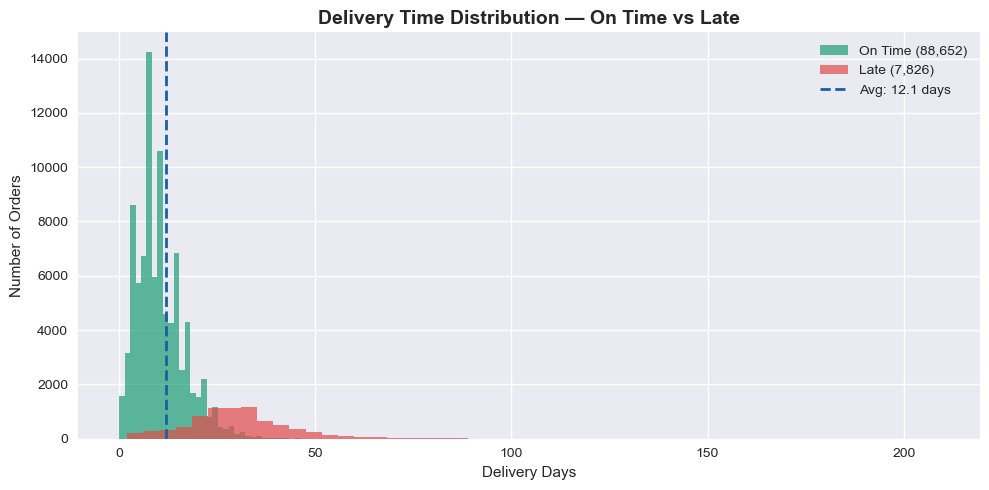

Chart 4 saved


In [6]:
# Chart 4 — Delivery time distribution
fig, ax = plt.subplots(figsize=(10, 5))

on_time = orders_clean[orders_clean['is_late'] == False]['delivery_days']
late = orders_clean[orders_clean['is_late'] == True]['delivery_days']

ax.hist(on_time, bins=50, alpha=0.7, color='#1D9E75', label=f'On Time ({len(on_time):,})')
ax.hist(late, bins=50, alpha=0.7, color='#E24B4A', label=f'Late ({len(late):,})')

ax.axvline(orders_clean['delivery_days'].mean(), color='#185FA5', 
           linestyle='--', linewidth=2, label=f'Avg: {orders_clean["delivery_days"].mean():.1f} days')

ax.set_title('Delivery Time Distribution — On Time vs Late', fontsize=14, fontweight='bold')
ax.set_xlabel('Delivery Days')
ax.set_ylabel('Number of Orders')
ax.legend()
plt.tight_layout()
plt.savefig('chart4_delivery_time.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 4 saved')

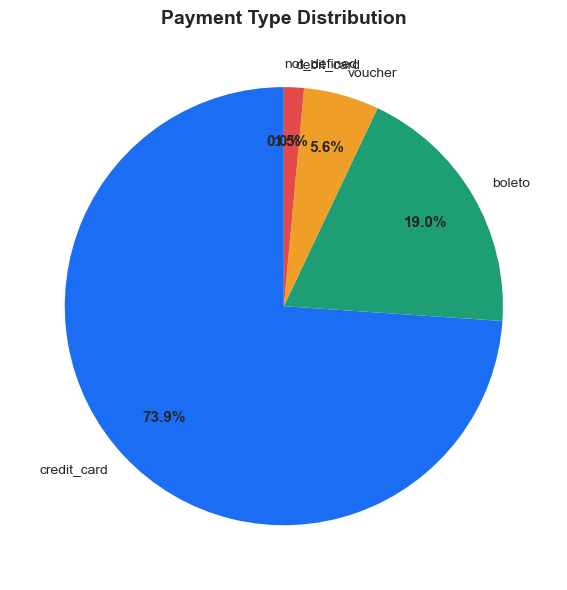

Chart 5 saved


In [7]:
# Chart 5 — Payment type breakdown
payment_counts = payments['payment_type'].value_counts()

colors = ['#1B6EF3', '#1D9E75', '#EF9F27', '#E24B4A', '#888780']
plt.figure(figsize=(8, 6))
wedges, texts, autotexts = plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    pctdistance=0.75
)
for text in autotexts:
    text.set_fontsize(11)
    text.set_fontweight('bold')

plt.title('Payment Type Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('chart5_payment_types.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 5 saved')

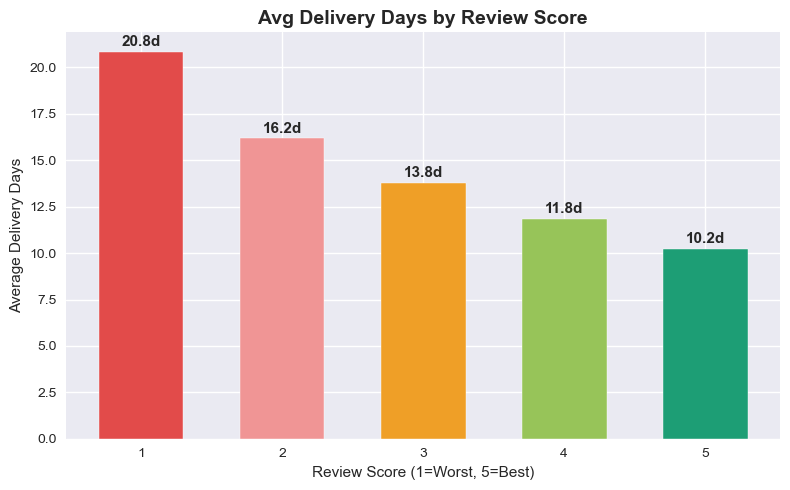

Chart 6 saved


In [8]:
# Chart 6 — Review score vs delivery days
merged = orders_clean.merge(reviews, on='order_id')
delivery_by_score = merged.groupby('review_score')['delivery_days'].mean().reset_index()

plt.figure(figsize=(8, 5))
bars = plt.bar(delivery_by_score['review_score'], 
               delivery_by_score['delivery_days'],
               color=['#E24B4A','#F09595','#EF9F27','#97C459','#1D9E75'],
               edgecolor='white', width=0.6)

for bar, val in zip(bars, delivery_by_score['delivery_days']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{val:.1f}d', ha='center', fontsize=11, fontweight='bold')

plt.title('Avg Delivery Days by Review Score', fontsize=14, fontweight='bold')
plt.xlabel('Review Score (1=Worst, 5=Best)')
plt.ylabel('Average Delivery Days')
plt.tight_layout()
plt.savefig('chart6_delivery_vs_review.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 6 saved')

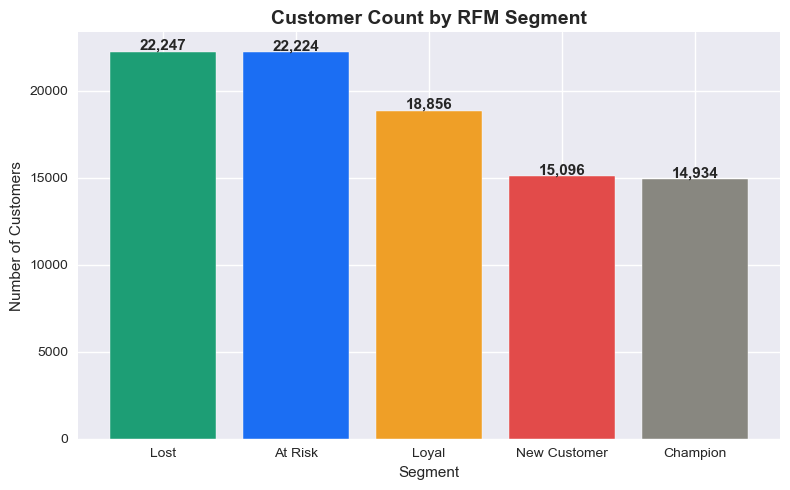

Chart 7 saved
Segment
Lost            22247
At Risk         22224
Loyal           18856
New Customer    15096
Champion        14934
Name: count, dtype: int64


In [9]:
# Chart 7 — RFM Customer Segments
snapshot_date = pd.Timestamp('2018-09-03')

df_rfm = orders_clean.merge(customers, on='customer_id').merge(payments, on='order_id')

rfm = df_rfm.groupby('customer_unique_id').agg(
    recency=('order_purchase_timestamp', lambda x: (snapshot_date - x.max()).days),
    frequency=('order_id', 'count'),
    monetary=('payment_value', 'sum')
).reset_index()

rfm['R'] = pd.qcut(rfm['recency'], 5, labels=[5,4,3,2,1])
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), 5, labels=[1,2,3,4,5])
rfm['M'] = pd.qcut(rfm['monetary'], 5, labels=[1,2,3,4,5])

def segment(row):
    r, f = int(row['R']), int(row['F'])
    if r >= 4 and f >= 4: return 'Champion'
    elif r >= 3 and f >= 3: return 'Loyal'
    elif r >= 4 and f <= 2: return 'New Customer'
    elif r <= 2 and f >= 3: return 'At Risk'
    else: return 'Lost'

rfm['Segment'] = rfm.apply(segment, axis=1)

seg_counts = rfm['Segment'].value_counts()
colors = ['#1D9E75','#1B6EF3','#EF9F27','#E24B4A','#888780']

plt.figure(figsize=(8, 5))
bars = plt.bar(seg_counts.index, seg_counts.values, color=colors, edgecolor='white')

for bar, val in zip(bars, seg_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
             f'{val:,}', ha='center', fontsize=11, fontweight='bold')

plt.title('Customer Count by RFM Segment', fontsize=14, fontweight='bold')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.savefig('chart7_rfm_segments.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 7 saved')
print(rfm['Segment'].value_counts())

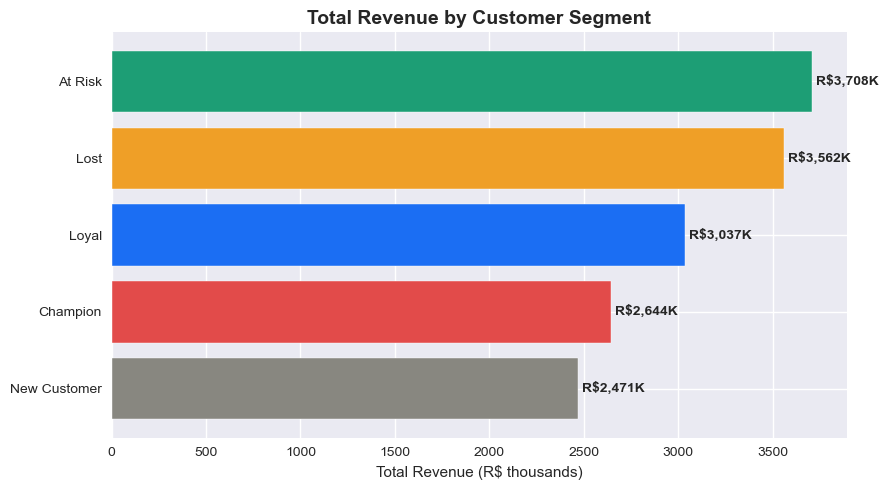

Chart 8 saved

Revenue summary:
                     sum    mean  count
Segment                                
At Risk       3708095.03  166.85  22224
Champion      2644373.95  177.07  14934
Lost          3561753.89  160.10  22247
Loyal         3037003.01  161.06  18856
New Customer  2471235.89  163.70  15096


In [10]:
# Chart 8 — Revenue by RFM Segment
seg_revenue = rfm.groupby('Segment')['monetary'].sum().sort_values(ascending=True)

plt.figure(figsize=(9, 5))
bars = plt.barh(seg_revenue.index, seg_revenue.values / 1000,
                color=['#888780','#E24B4A','#1B6EF3','#EF9F27','#1D9E75'],
                edgecolor='white')

for bar, val in zip(bars, seg_revenue.values):
    plt.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2,
             f'R${val/1000:,.0f}K', va='center', fontsize=10, fontweight='bold')

plt.title('Total Revenue by Customer Segment', fontsize=14, fontweight='bold')
plt.xlabel('Total Revenue (R$ thousands)')
plt.tight_layout()
plt.savefig('chart8_revenue_by_segment.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 8 saved')
print('\nRevenue summary:')
print(rfm.groupby('Segment')['monetary'].agg(['sum','mean','count']).round(2))